# **Лабораторная работа 1. Работа с графами.**

## Черных Богдан, БИВТ-24-9

**Предварительная подготовка.**

**СКОПИРУЙТЕ ФАЙЛ**

ОБЯЗАТЕЛЬНО ЗДЕСЬ НАПИШИТЕ ФАМИЛИЮ.

Сдаете в LMS вы ipynb версию скачанную (не colab). При необходимости, вы можете сдать дополнительно файл (офомленный в любом читаемом виде).

Пожалуйста, не надо использовать ИИ для ответов на вопросы и написания кода. Отвечать на вопросы лучше прям здесь, под заданиями, где были написаны вопросыю

**Цель:** изучить алгоритмы поиска в глубину (DFS) и в ширину (BFS), реализовать их для разных представлений графа, проанализировать сложность и сравнить производительность экспериментально.

# 1. Изучите ```perf_counter()``` и ```perf_counter_ns()```.

`perf_counter()` и `perf_counter_ns()` — это функции из модуля `time`, предоставляющие **доступ к высокоточным таймерам**.

Посмотрите на пример измерения времени работы какого-то фрагмента кода.

In [29]:
import time

# perf_counter() — возвращает время в СЕКУНДАХ (float)
start = time.perf_counter()
s = sum(range(100000))  # некоторый измеряемый фрагмент кода
end = time.perf_counter()
print(end - start)

# perf_counter_ns() — возвращает время в НАНОСЕКУНДАХ (int)
start_ns = time.perf_counter_ns()
s = sum(range(100000)) # некоторый измеряемый фрагмент кода
end_ns = time.perf_counter_ns()
print(end_ns - start_ns)

0.002040400002442766
1859500


# 2. Как проводить измерение времени работы алгоритма и глубины рекурсии (для рекурсивных алгоритмов)

Напишем простую рекурсивную функцию для подсчета факториала числа. И на её примере посмотрим как измерять время работы алгоритма, а также глубину рекурсии.

In [30]:
import sys
sys.setrecursionlimit(10000)
def factorial(n):
    if n <= 1:
        return 1
    return n * factorial(n-1)

Проведем анализ сложности этой функции.

Для нее верно следующее рекуррентное соотношение
```
T(n) = T(n-1) + O(1)
T(1) = O(1)
```

Выполним процесс развертывания рекурсивной функции.

```
T(n) = T(n-1) + 1
T(n) = [T(n-2) + 1] + 1 = T(n-2) + 2
T(n) = [T(n-3) + 1] + 2 = T(n-3) + 3
```

**на шаге k получим**
```
T(n) = T(n-k) + k
```
При k = n-1 достигнем базового случая (доходим до T(1)):

```
T(n) = T(1) + (n-1)
T(n) = 1 + (n-1)
T(n) = n
```

**Временная сложность:** **O(n)** — линейная

## Анализ времени (через функцию измерения времени)

Напишем функцию, которая измеряет время работы этой функции на разных размерах входных данных, чтобы на реальных замерах убедиться, что время работы функции линейное.

In [31]:
def measure_factorial_time(n, repeats=10): # repeats число повторов для одной сессии измерений
    times = []

    for _ in range(repeats):
        start = time.perf_counter_ns()
        result = factorial(n)
        end = time.perf_counter_ns()
        times.append(end - start)

    # убираем выбросы (минимальное и максимальное время) и усредняем
    if repeats > 2:
        times.sort()
        times = times[1:-1]

    avg_time = sum(times) / len(times)
    return avg_time, result

times_ns = [] # тут будет время работы
init_n = list(range(100, 1001, 50)) # тут будут исходные размеры входных данных

for n in init_n:
    time_ns, _ = measure_factorial_time(n, repeats=10)
    times_ns.append(time_ns)

Теперь визуализируем результаты, чтобы на графике убедиться в корректности наших выводов о времени работы функции.

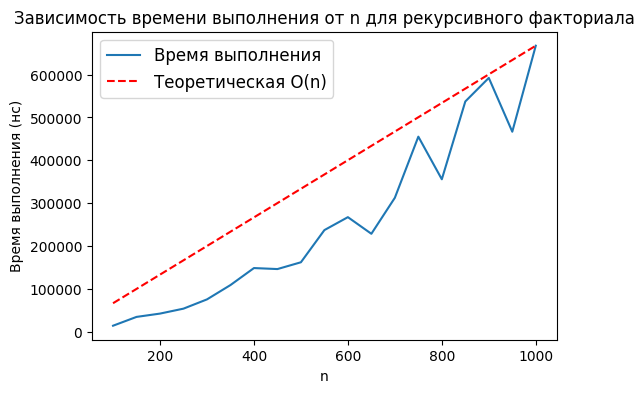

In [32]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6, 4))
plt.plot(init_n, times_ns, label='Время выполнения')

import numpy as np
theoretical_log = [n for n in init_n]
scale_factor = max(times_ns) / max(theoretical_log)
theoretical_time = [t * scale_factor for t in theoretical_log]
plt.plot(init_n, theoretical_time, 'r--', label='Теоретическая O(n)')

plt.xlabel('n')
plt.ylabel('Время выполнения (нс)')
plt.title('Зависимость времени выполнения от n для рекурсивного факториала')
plt.legend(fontsize=12, loc='upper left')

Измерение времени зависит от множества факторов: загрузки процессора, фоновых процессов, и даже (внезапно!) температуры CPU и т.д. Сегодня алгоритм выполняется 1.2 мс, завтра -- 1.5 мс, и непонятно, что изменилось. Поэтому используют еще один подход -- измеряют количество операций. Ведь количество операций -- детерминировано: для факториала 5 всегда будет 5 умножений.

## Анализ времени (через измерение числа операций)

Перепишем функцию факториала, чтобы можно было измерить число операций. К сожалению, придется немного испортить нашу функцию.

In [33]:
def factorial(n):
    def _fact(n):
        nonlocal operations
        operations += 1  # каждая проверка условия - операция
        if n <= 1:
            return 1
        operations += 3
        # умножение, вычитание и вызов функции это еще три операции
        return n * _fact(n-1)

    operations = 0
    result = _fact(n)
    return result, operations

In [34]:
def count_factorial_operations(n, repeats=10):
    times = []
    result = None

    for _ in range(repeats):
        result, ops = factorial(n)

    return result, ops

init_n = list(range(100, 1001, 50))
times_ns = []
operations_list = []

for n in init_n:
    _, ops = count_factorial_operations(n, repeats=10)
    operations_list.append(ops)

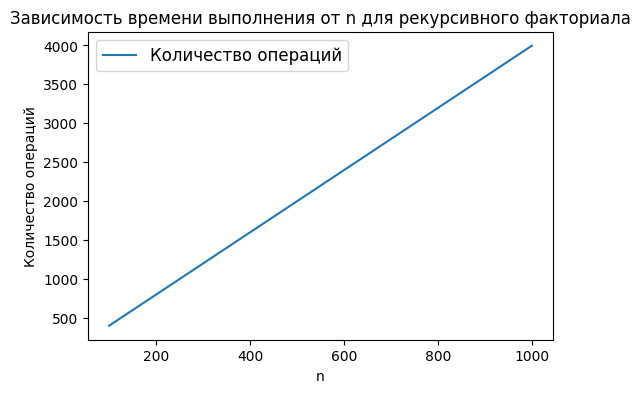

In [35]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6, 4))
plt.plot(init_n, operations_list, label='Количество операций')

plt.xlabel('n')
plt.ylabel('Количество операций')
plt.title('Зависимость времени выполнения от n для рекурсивного факториала')
plt.legend(fontsize=12, loc='upper left')

Обратите внимание, на графике нет выбросов и зависимость более четкая. Также не нужно выполнять несколько повторов.

## Анализ глубины рекурсии

Перепишем функцию, чтобы можно было измерить максимальную глубину рекурсии

In [36]:
def factorial(n):
    def _fact(n, depth):
        nonlocal max_depth
        max_depth = max(max_depth, depth)

        if n <= 1:
            return 1

        return n * _fact(n-1, depth + 1)

    max_depth = 0
    result = _fact(n, 1)  # начинаем с глубины 1
    return result, max_depth

init_n = list(range(100, 1001, 50))
depth_list = []

for n in init_n:
    _, depth = factorial(n)
    depth_list.append(depth)

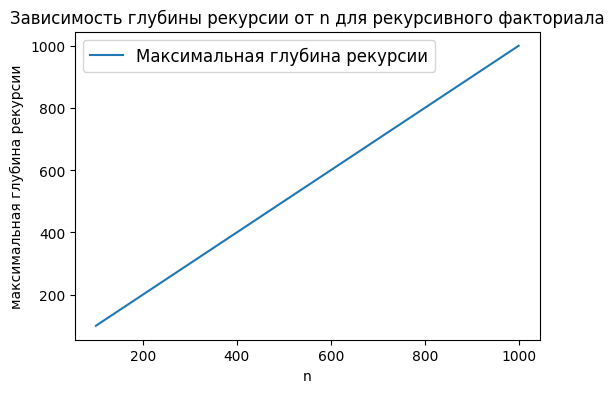

In [37]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6, 4))
plt.plot(init_n, depth_list, label='Максимальная глубина рекурсии')

plt.xlabel('n')
plt.ylabel('максимальная глубина рекурсии')
plt.title('Зависимость глубины рекурсии от n для рекурсивного факториала')
plt.legend(fontsize=12, loc='upper left')

Фактически, в данном примере, для нас глубина рекурсии показывает количество используемой памяти. Видим, что максимальная глубина рекурсии линейно зависит от размера входных данных. Учитывая, что на каждом вызове у нас создается/копируется константное количество переменных -- память используемая (то есть пространтсвенная сложность) **O(N)**

 # Предварительная подготовка, работа с библиотекой `NetworkX`

В этом задании будет выполнена предварительная подготовка, которая вам пригодится для выполнения заданий. Будем говорить о генерации графов разной плотности.

**Плотность графа** определяется как отношение количества рёбер к максимально возможному:
- Для **неориентированного графа** без петель: максимум рёбер = n·(n-1)/2
- Для **ориентированного графа** без петель: максимум рёбер = n·(n-1)

**Классификация:**
- **Разреженный (sparse):** E ≈ O(V)
- **Средней плотности:** E ≈ O(V·log V)
- **Плотный (dense):** E ≈ O(V²)


Мы будем для генерации использовать библиотеку `NetworkX`

Сначала её нужно установить.

In [38]:
!pip install networkx matplotlib

"pip" �� ���� ����७��� ��� ���譥�
��������, �ᯮ��塞�� �ணࠬ��� ��� ������ 䠩���.


Ниже посмотрим основные возможности библиотеки.

**Ориентированный и неориентированный граф (создание)**


In [39]:
import networkx as nx

G = nx.Graph() # Неориентированный граф
DG = nx.DiGraph() # Ориентированный граф

G.add_node(1) # Добавление вершин
G.add_nodes_from([2, 3, 4])

G.add_edge(1, 2) # Добавление рёбер
G.add_edges_from([(1, 3), (2, 3), (3, 4)])

G.add_edge(1, 2, weight=5) # С взвешенными рёбрами
G.add_edge(2, 3, weight=3)

**Разные методы и атрибуты графа**

In [40]:
print(f"Вершин: {G.number_of_nodes()}") # Количество вершин и рёбер
print(f"Рёбер: {G.number_of_edges()}")

print(f"Вершины: {list(G.nodes())}") # Список вершин и рёбер
print(f"Рёбра: {list(G.edges())}")

print(f"Соседи вершины 3: {list(G.neighbors(3))}") # Соседи вершины

print(f"Степень вершины 2: {G.degree(2)}") # Степень вершины

print(f"Есть ли ребро (1,3)? {G.has_edge(1, 3)}") # Проверка наличия ребра

G.remove_edge(1, 2) # Удаление ребра/вершины
G.remove_node(4)

Вершин: 4
Рёбер: 4
Вершины: [1, 2, 3, 4]
Рёбра: [(1, 2), (1, 3), (2, 3), (3, 4)]
Соседи вершины 3: [1, 2, 4]
Степень вершины 2: 2
Есть ли ребро (1,3)? True


**Визуализация графа**

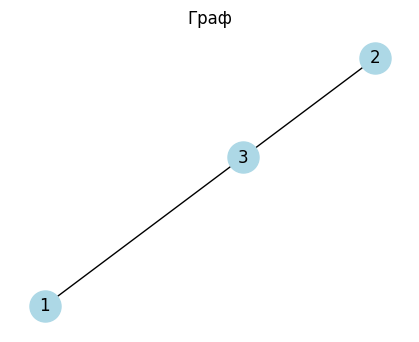

In [41]:
import matplotlib.pyplot as plt

plt.figure(figsize=(4, 3))
nx.draw(G, with_labels=True, node_color='lightblue',
        node_size=500, font_size=12)
plt.title("Граф")
plt.show()

**Алгоритмы на графах**

Правда, в нашем задании вам нужно будет реализовать свои, но полезно знать и библиотечные, чтобы можно было сравнить результаты.

In [42]:
print(f"Кратчайший путь с 1 до 3: {nx.shortest_path(G, source=1, target=3)}")
print(f"Длина пути: {nx.shortest_path_length(G, source=1, target=3)}")
print(f"Все пути: {list(nx.all_shortest_paths(G, source=1, target=3))}")
print(f"Компоненты связности: {list(nx.connected_components(G))}")
bfs = list(nx.bfs_tree(G, source=1))
dfs = list(nx.dfs_tree(G, source=1))
print(f"BFS: {bfs}")
print(f"DFS: {dfs}")

Кратчайший путь с 1 до 3: [1, 3]
Длина пути: 1
Все пути: [[1, 3]]
Компоненты связности: [{1, 2, 3}]
BFS: [1, 3, 2]
DFS: [1, 3, 2]


**Сохранение графа**

Рекомендуем ваши сгенерированные графы сохранить, чтобы потом не перегенерировать их заново.

In [43]:
# Так можно сохранить граф в файл, в специальном формате или же списком ребер
nx.write_graphml(G, "graph.graphml")
nx.write_edgelist(G, "edges.txt")

# А так можно будет загрузить граф
G_loaded = nx.read_graphml("graph.graphml")

### Так можно генерировать графы

**Случайный граф Эрдёша-Реньи.**


**Модель Эрдёша-Реньи** -- это классическая модель случайного графа, названная в честь венгерских математиков **Пала Эрдёша** и **Альфреда Реньи**, которые предложили её в 1959 году.

Идея генерации тут такая. Представьте, что у вас есть n вершин, и вы случайным образом проводите между ними рёбра. Модель Эрдёша-Реньи описывает два способа, как это можно сделать.

**Модель генерации erdos_renyi_graph(n, p) -- с вероятностью p**
- `n` -- количество вершин
- `p` -- вероятность того, что между любой парой вершин существует ребро (0 ≤ p ≤ 1)

**Как работает**
- Берём все возможные пары вершин (всего C(n,2) = n·(n-1)/2 пар)
- Для каждой пары независимо подбрасываем монетку с вероятностью успеха p
- Если успех -- добавляем ребро, если нет -- не добавляем

**Количество рёбер** -- случайное, в среднем p·C(n,2)

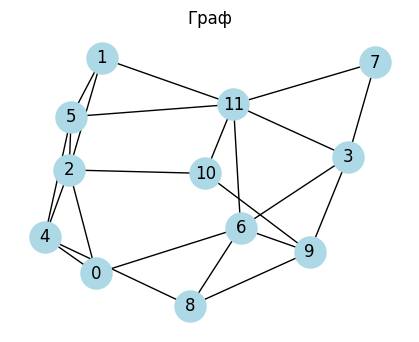

In [44]:
G_er = nx.erdos_renyi_graph(12, 0.3)
plt.figure(figsize=(4, 3))
nx.draw(G_er, with_labels=True, node_color='lightblue',
        node_size=500, font_size=12)
plt.title("Граф")
plt.show()

**Классический полный граф**

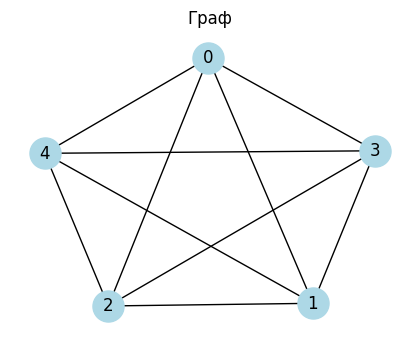

In [45]:
G_complete = nx.complete_graph(5)
plt.figure(figsize=(4, 3))
nx.draw(G_complete, with_labels=True, node_color='lightblue',
        node_size=500, font_size=12)
plt.title("Граф")
plt.show()

**Граф цикл**

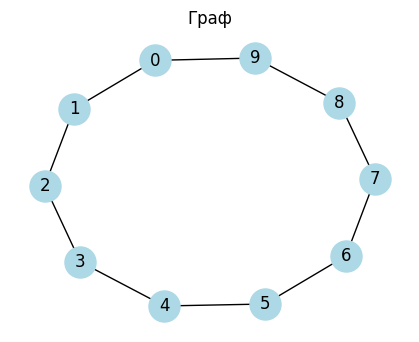

In [46]:
G_cycle = nx.cycle_graph(10)
plt.figure(figsize=(4, 3))
nx.draw(G_cycle, with_labels=True, node_color='lightblue',
        node_size=500, font_size=12)
plt.title("Граф")
plt.show()

**Сбалансированное дерево (balanced tree)** -- структура данных, в которой каждый узел имеет одинаковое количество потомков, а все листья находятся на примерно одинаковой глубине.

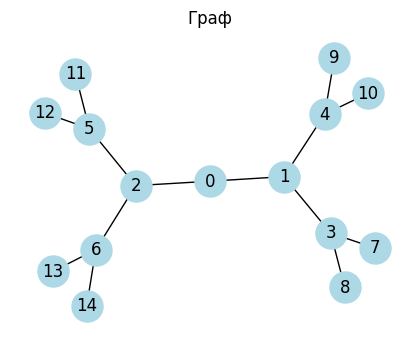

In [47]:
G_tree = nx.balanced_tree(2, 3) # количество потомков, высота
plt.figure(figsize=(4, 3))
nx.draw(G_tree, with_labels=True, node_color='lightblue',
        node_size=500, font_size=12)
plt.title("Граф")
plt.show()

**Как сделать взвешенный граф**

Используйте строго seed = 42

In [48]:
import random

def add_random_weights(G, weight_range=(1, 10), seed=None):
    if seed is not None:
        random.seed(seed)

    for u, v in G.edges():
        G[u][v]['weight'] = random.randint(weight_range[0], weight_range[1])

    return G

G_cycle = nx.cycle_graph(10)
G_cycle = add_random_weights(G_cycle, seed=42)

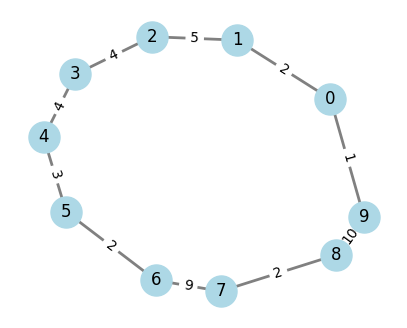

In [49]:
plt.figure(figsize=(5, 4))
pos = nx.spring_layout(G_cycle, seed=42)
nx.draw_networkx_nodes(G_cycle, pos, node_color='lightblue',
                      node_size=500) # Рисуем вершины
nx.draw_networkx_labels(G_cycle, pos, font_size=12)
nx.draw_networkx_edges(G_cycle, pos, width=2, edge_color='gray') # Рисуем рёбра
edge_labels = nx.get_edge_attributes(G_cycle, 'weight') # Добавляем веса
nx.draw_networkx_edge_labels(G_cycle, pos, edge_labels=edge_labels,
                            font_size=10)
plt.axis('off')
plt.show()

# Задание 1 (1 балл)

Сгенерировать набор графов для последующего тестирования алгоритмов, используя библиотеку NetworkX.

**Размеры графов:**
- Количество вершин: от **10 до 1010**
- Шаг: **50** вершин
- Для каждого размера случайного графа сделать **5 графов**. Когда его будете тестировать, нужно делать тест на всех пяти графах одного размера и усреднять результат.

Обязательно, не забудьте, делать граф взвешенным (пригодится для задания 5).

Для случайново графа использовать seed = 42 (random).

**Каждого размера должно быть сгенерировано три типа графов (для разных случаев):**

| Тип | Описание | Случай |
|-----|----------|--------|
| **Полный граф** (complete graph) | Все вершины соединены со всеми | Скорее всего, это будет худший случай (максимум рёбер) |
| **Дерево** (tree) | Минимально связный граф (n-1 рёбер) | Скорее всего, это будет лучший случай (минимум рёбер) |
| **Случайный связный** | Эрдёша-Реньи c заданным seed random 42| Средний случай. Правда, может получиться не связным, вам это нужно учесть при запусках алгоритмов. |

**Сохранить графы таким образом (структура выходных данных)**

```
graphs_dataset/
├── complete/          # полные графы (худший случай)
│   ├── graph_n0010_1.txt
│   ├── graph_n0010_2.txt
│   └── ...
├── tree/              # деревья (лучший случай)
│   ├── graph_n0010_1.txt
│   └── ...
└── random/            # случайные связные (средний случай)
    ├── graph_n0010_1.txt
    └── ...
```

## Формат файла должен быть -- список рёбер

```
n m
5 5
1 3 5
2 7 4
...
```

где:
- первая строка: `n` (число вершин) и `m` (число рёбер)
- следующие `m` строк: ребра в формате `u v с` (нумерация с 0), откуда - куда - вес ребра

In [50]:
import os
import random

random.seed(42)
graph_sizes = list(range(10, 1011, 50))
samples_per_size = 5
graph_types = ["complete", "tree", "random"]

for graph_type in graph_types:
    os.makedirs(os.path.join("graphs_dataset", graph_type), exist_ok=True)

for size_index, n in enumerate(graph_sizes):
    for sample_index in range(samples_per_size):
        seed = 42 + size_index * samples_per_size + sample_index

        for graph_type in graph_types:
            if graph_type == "complete":
                graph = nx.complete_graph(n)
            elif graph_type == "tree":
                graph = nx.random_labeled_tree(n, seed=seed)
            else:
                graph = nx.erdos_renyi_graph(n, 0.3, seed=seed)

            graph = add_random_weights(graph, seed=seed + 100000)
            file_name = "graph_n{:04d}_{}.txt".format(
                n, sample_index + 1
            )
            file_path = os.path.join(
                "graphs_dataset", graph_type, file_name
            )

            with open(file_path, "w", encoding="utf-8") as graph_file:
                graph_file.write("{} {}\n".format(
                    graph.number_of_nodes(), graph.number_of_edges()
                ))

                for first, second, data in graph.edges(data=True):
                    graph_file.write("{} {} {}\n".format(
                        first, second, data["weight"]
                    ))

def dataset_files(graph_type, n):
    file_paths = []
    sample_index = 1

    while sample_index <= samples_per_size:
        file_name = "graph_n{:04d}_{}.txt".format(n, sample_index)
        file_path = os.path.join(
            "graphs_dataset", graph_type, file_name
        )
        file_paths.append(file_path)
        sample_index = sample_index + 1

    return file_paths

def read_graph_file(file_path, representation):
    with open(file_path, "r", encoding="utf-8") as graph_file:
        first_line = graph_file.readline().split()
        n = int(first_line[0])
        edge_count = int(first_line[1])

        if representation == "edges":
            graph_data = []
        elif representation == "plain":
            graph_data = []
            vertex = 0

            while vertex < n:
                graph_data.append([])
                vertex = vertex + 1
        else:
            graph_data = []
            vertex = 0

            while vertex < n:
                graph_data.append([])
                vertex = vertex + 1

        for line in graph_file:
            values = line.split()
            first = int(values[0])
            second = int(values[1])
            weight = int(values[2])

            if representation == "edges":
                graph_data.append((first, second, weight))
            elif representation == "plain":
                graph_data[first].append(second)
                graph_data[second].append(first)
            else:
                graph_data[first].append((second, weight))
                graph_data[second].append((first, weight))

    return n, graph_data

print("Создано графов:", len(graph_types) * len(graph_sizes) * samples_per_size)

Создано графов: 315


# Задание 2 (2 балла)

В этом задании мы исследуем различные способы представления графов в памяти компьютера и сравним их.

Рассмотрим три основных способа представления графов.

**1. Матрица смежности (Adjacency Matrix).**
Двумерный массив размером `|V| × |V|`, где `matrix[i][j] = 1`, если есть ребро из вершины `i` в вершину `j`, и `matrix[i][j] = 0` в противном случае.

**2. Список смежности (Adjacency List)**
Массив списков (или динамических массивов) размером `|V|`, где `list[i]` содержит всех соседей вершины `i`.

**3. Список рёбер (Edge List)**
Обычный список, каждый элемент которого — это кортеж `(u, v)` или `(u, v, weight)` для взвешенных графов.

Вам нужно экспериментально проверить теоретические оценки сложности операций над графами для трёх основных способов представления:
* Матрица смежности
* Список смежности
* Список рёбер

Реализуйте классы для трёх способов представления графа, вы можете добавлять дополнительные методы. Используйте глобальную переменную `operations_count` для подсчёта операций (как в примере с факториалом).

In [51]:
operations_count = 0

class AdjacencyMatrix:
    def __init__(self, n):
        self.V = n
        self.matrix = [[0] * n for _ in range(n)]

    def add_edge(self, u, v):
        global operations_count
        self.matrix[u][v] = 1
        self.matrix[v][u] = 1
        operations_count = operations_count + 2
        return True

    def remove_edge(self, u, v):
        global operations_count
        existed = self.matrix[u][v] == 1
        self.matrix[u][v] = 0
        self.matrix[v][u] = 0
        operations_count = operations_count + 2
        return existed

    def has_edge(self, u, v):
        global operations_count
        operations_count = operations_count + 1
        return self.matrix[u][v] == 1

    def add_vertex(self):
        global operations_count
        new_matrix = []

        for row in self.matrix:
            new_row = row[:]
            new_row.append(0)
            new_matrix.append(new_row)
            operations_count = operations_count + self.V + 1

        new_matrix.append([0] * (self.V + 1))
        operations_count = operations_count + self.V + 1
        self.matrix = new_matrix
        self.V = self.V + 1
        return self.V - 1

    def remove_vertex(self, v):
        global operations_count
        shift_count = self.V - v - 1

        for row in self.matrix:
            row.pop(v)
            operations_count = operations_count + shift_count

        self.matrix.pop(v)
        operations_count = operations_count + shift_count
        self.V = self.V - 1
        return True

    def is_isolated(self, v):
        global operations_count

        for neighbor in range(self.V):
            operations_count = operations_count + 1

            if self.matrix[v][neighbor] == 1:
                return False

        return True

In [52]:
operations_count = 0

class AdjacencyList:
    def __init__(self, n):
        self.V = n
        self.adj_list = [[] for _ in range(n)]

    def add_edge(self, u, v):
        global operations_count
        self.adj_list[u].append(v)

        if u != v:
            self.adj_list[v].append(u)
            operations_count = operations_count + 2
        else:
            operations_count = operations_count + 1

        return True

    def remove_edge(self, u, v):
        global operations_count
        removed = False
        index = 0

        while index < len(self.adj_list[u]):
            operations_count = operations_count + 1

            if self.adj_list[u][index] == v:
                shift_count = len(self.adj_list[u]) - index - 1
                self.adj_list[u].pop(index)
                operations_count = operations_count + shift_count
                removed = True
                break

            index = index + 1

        if u != v:
            index = 0

            while index < len(self.adj_list[v]):
                operations_count = operations_count + 1

                if self.adj_list[v][index] == u:
                    shift_count = len(self.adj_list[v]) - index - 1
                    self.adj_list[v].pop(index)
                    operations_count = operations_count + shift_count
                    break

                index = index + 1

        return removed

    def has_edge(self, u, v):
        global operations_count

        for neighbor in self.adj_list[u]:
            operations_count = operations_count + 1

            if neighbor == v:
                return True

        return False

    def add_vertex(self):
        global operations_count
        self.adj_list.append([])
        self.V = self.V + 1
        operations_count = operations_count + 1
        return self.V - 1

    def remove_vertex(self, v):
        global operations_count
        new_adj_list = []

        for vertex in range(self.V):
            if vertex == v:
                operations_count = operations_count + len(
                    self.adj_list[vertex]
                )
                continue

            new_neighbors = []

            for neighbor in self.adj_list[vertex]:
                operations_count = operations_count + 1

                if neighbor != v:
                    if neighbor > v:
                        neighbor = neighbor - 1

                    new_neighbors.append(neighbor)

            new_adj_list.append(new_neighbors)

        self.adj_list = new_adj_list
        self.V = self.V - 1
        return True

    def is_isolated(self, v):
        global operations_count
        operations_count = operations_count + 1
        return len(self.adj_list[v]) == 0

In [53]:
operations_count = 0

class EdgeList:
    def __init__(self, n):
        self.V = n
        self.edges = []
        self.vertices = set(range(n))

    def add_edge(self, u, v):
        global operations_count
        edge = (u, v)

        if u > v:
            edge = (v, u)

        self.edges.append(edge)
        operations_count = operations_count + 1
        return True

    def remove_edge(self, u, v):
        global operations_count
        edge = (u, v)

        if u > v:
            edge = (v, u)

        index = 0

        while index < len(self.edges):
            operations_count = operations_count + 1

            if self.edges[index] == edge:
                self.edges.pop(index)
                return True

            index = index + 1

        return False

    def has_edge(self, u, v):
        global operations_count
        edge = (u, v)

        if u > v:
            edge = (v, u)

        for current_edge in self.edges:
            operations_count = operations_count + 1

            if current_edge == edge:
                return True

        return False

    def add_vertex(self):
        global operations_count
        new_vertex = self.V
        self.vertices.add(new_vertex)
        self.V = self.V + 1
        operations_count = operations_count + 1
        return new_vertex

    def remove_vertex(self, v):
        global operations_count
        new_edges = []

        for first, second in self.edges:
            operations_count = operations_count + 1

            if first == v or second == v:
                continue

            if first > v:
                first = first - 1

            if second > v:
                second = second - 1

            new_edges.append((first, second))

        new_vertices = set()

        for vertex in range(self.V):
            operations_count = operations_count + 1

            if vertex != v:
                if vertex > v:
                    vertex = vertex - 1

                new_vertices.add(vertex)

        self.edges = new_edges
        self.vertices = new_vertices
        self.V = self.V - 1
        return True

    def is_isolated(self, v):
        global operations_count

        for first, second in self.edges:
            operations_count = operations_count + 1

            if first == v or second == v:
                return False

        return True

Для каждого типа представления и каждой операции измерьте для плотных графов (худший случай) размера от 10 до 1010 с шагом 50 измерьте количество операций. Используйте ранее сохраненные графы для экспериментов.

Постройте графики зависимости количества операций от размера графа по типам операции. На каждом графике должны быть три линии (матрица, список, список рёбер).

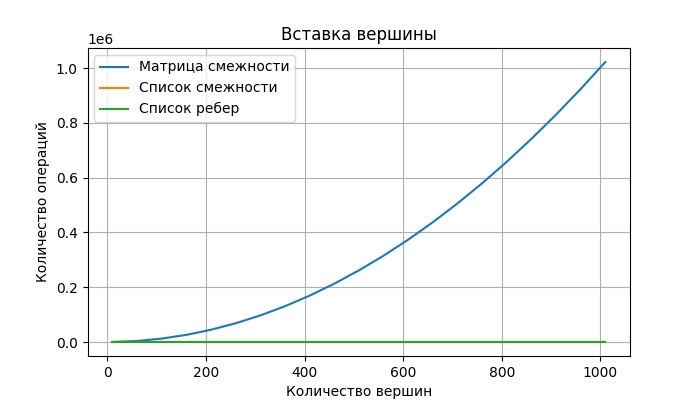

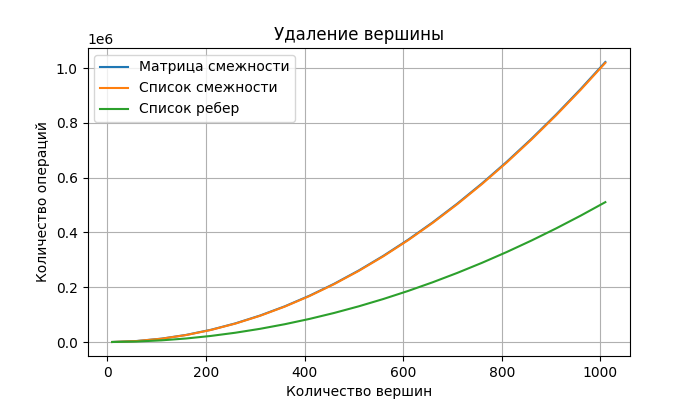

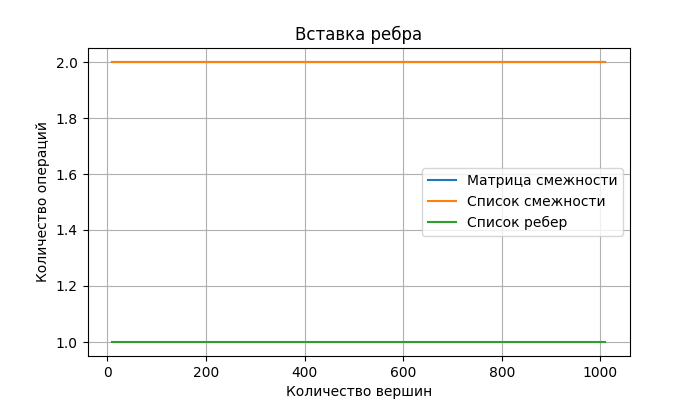

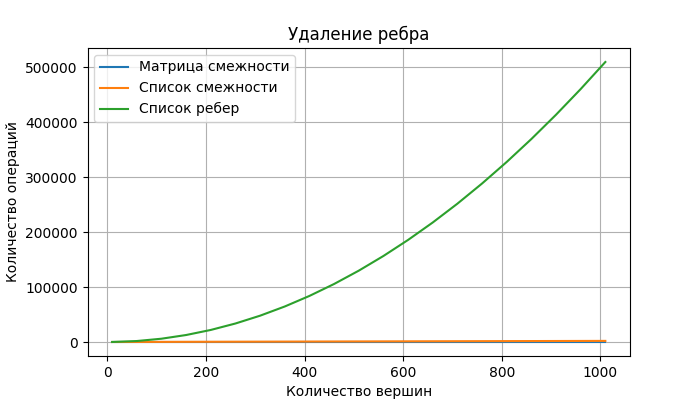

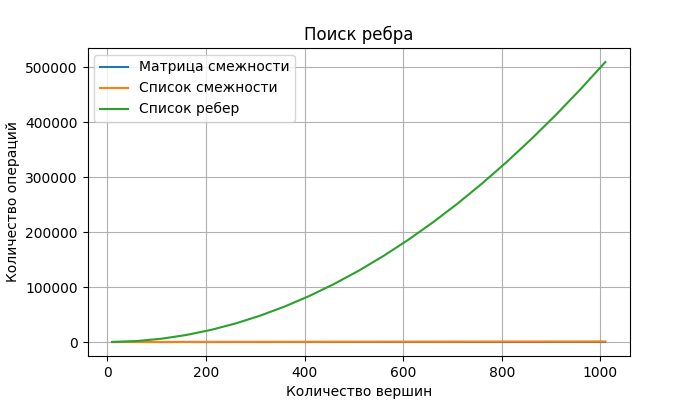

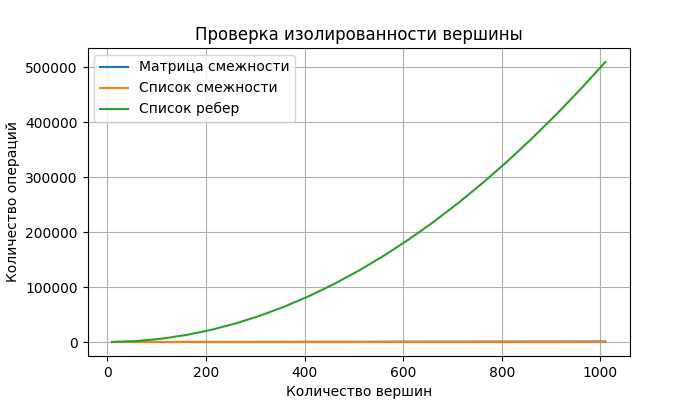

In [54]:
graph_sizes = list(range(10, 1011, 50))
representation_classes = [
    ("Матрица смежности", AdjacencyMatrix),
    ("Список смежности", AdjacencyList),
    ("Список ребер", EdgeList),
]
operation_names = [
    "Вставка вершины",
    "Удаление вершины",
    "Вставка ребра",
    "Удаление ребра",
    "Поиск ребра",
    "Изолированность",
]
operation_results = {}

for representation_name, representation_class in representation_classes:
    operation_results[representation_name] = {}

    for operation_name in operation_names:
        operation_results[representation_name][operation_name] = []

for n in graph_sizes:
    operation_totals = {}

    for representation_name, representation_class in representation_classes:
        operation_totals[representation_name] = {}

        for operation_name in operation_names:
            operation_totals[representation_name][operation_name] = 0

    for file_path in dataset_files("complete", n):
        graph_n, edges = read_graph_file(file_path, "edges")

        for representation_name, representation_class in representation_classes:
            graph = representation_class(graph_n)

            if representation_name == "Матрица смежности":
                for first, second, weight in edges:
                    graph.matrix[first][second] = 1
                    graph.matrix[second][first] = 1
            elif representation_name == "Список смежности":
                for first, second, weight in edges:
                    graph.adj_list[first].append(second)
                    graph.adj_list[second].append(first)
            else:
                for first, second, weight in edges:
                    graph.edges.append((first, second))

            first_vertex = graph_n - 2
            last_vertex = graph_n - 1
            operations_count = 0
            graph.has_edge(first_vertex, last_vertex)
            operation_totals[representation_name]["Поиск ребра"] = (
                operation_totals[representation_name]["Поиск ребра"]
                + operations_count
            )

            operations_count = 0
            graph.remove_edge(first_vertex, last_vertex)
            operation_totals[representation_name]["Удаление ребра"] = (
                operation_totals[representation_name]["Удаление ребра"]
                + operations_count
            )

            operations_count = 0
            graph.add_edge(first_vertex, last_vertex)
            operation_totals[representation_name]["Вставка ребра"] = (
                operation_totals[representation_name]["Вставка ребра"]
                + operations_count
            )

            operations_count = 0
            new_vertex = graph.add_vertex()
            operation_totals[representation_name]["Вставка вершины"] = (
                operation_totals[representation_name]["Вставка вершины"]
                + operations_count
            )

            operations_count = 0
            graph.is_isolated(new_vertex)
            operation_totals[representation_name]["Изолированность"] = (
                operation_totals[representation_name]["Изолированность"]
                + operations_count
            )

            operations_count = 0
            graph.remove_vertex(0)
            operation_totals[representation_name]["Удаление вершины"] = (
                operation_totals[representation_name]["Удаление вершины"]
                + operations_count
            )


    for representation_name, representation_class in representation_classes:
        for operation_name in operation_names:
            average = operation_totals[representation_name][operation_name]
            average = average / samples_per_size
            operation_results[representation_name][operation_name].append(
                average
            )

operation_titles = {
    "Вставка вершины": "Вставка вершины",
    "Удаление вершины": "Удаление вершины",
    "Вставка ребра": "Вставка ребра",
    "Удаление ребра": "Удаление ребра",
    "Поиск ребра": "Поиск ребра",
    "Изолированность": "Проверка изолированности вершины",
}

for operation_name in operation_names:
    plt.figure(figsize=(7, 4))

    for representation_name, representation_class in representation_classes:
        values = operation_results[representation_name][operation_name]
        plt.plot(graph_sizes, values, label=representation_name)

    plt.xlabel("Количество вершин")
    plt.ylabel("Количество операций")
    plt.title(operation_titles[operation_name])
    plt.legend()
    plt.grid(True)
    plt.show()

По результатам экспериментов заполните таблицу:

| Операция | Матрица смежности | Список смежности | Список рёбер |
|----------|-------------------|-------------------|--------------|
| **Память** | O(V²) | O(V + E) | O(V + E) |
| **Инициализация** | O(V²) | O(V) | O(V) |
| **Вставка вершины** | O(V²) | O(1) | O(1) |
| **Удаление вершины** | O(V²) | O(V + E) | O(V + E) |
| **Вставка ребра** | O(1) | O(1) | O(1) |
| **Поиск/удаление ребра** | O(1) | O(deg(v)) | O(E) |
| **Проверка изолированности вершины** | O(V) | O(1) | O(E) |

V — количество вершин, E — количество ребер, deg(v) — степень вершины

**Ответьте на контрольные вопросы ниже:**
1. Совпадают ли экспериментальные результаты с теоретическими оценками?
2. Для каких операций разница наиболее заметна?
3. Почему вставка вершины в матрицу смежности требует O(V²)?
4. Почему список рёбер так плох для операции поиска ребра?
5. Какой способ представления лучше всего подходит для:
* Алгоритма Дейкстры?
* Алгоритма Флойда?
* BFS/DFS?
* Хранения разреженных графов?
* Хранения плотных графов?

In [55]:
print(
    "1. Измерения в основном следуют ожидаемым оценкам. "
    "Вставка ребра и проверка в матрице требуют постоянного числа "
    "операций, а обход списка ребер растет вместе с числом ребер.\n"
    "2. Разница особенно заметна при поиске или удалении ребра "
    "в списке ребер и при добавлении или удалении вершины в матрице.\n"
    "3. При вставке вершины матрицу размером V на V приходится "
    "пересоздать с новыми строкой и столбцом. Копирование старых "
    "V² элементов дает сложность O(V²).\n"
    "4. В обычном списке ребер ребро приходится искать последовательным "
    "просмотром до E записей, поэтому поиск занимает O(E).\n"
    "5. Дэйкстра: список смежности; Флойд: матрица; BFS/DFS: "
    "список смежности; разреженный граф: список смежности; "
    "плотный граф: матрица смежности."
    )

1. Измерения в основном следуют ожидаемым оценкам. Вставка ребра и проверка в матрице требуют постоянного числа операций, а обход списка ребер растет вместе с числом ребер.
2. Разница особенно заметна при поиске или удалении ребра в списке ребер и при добавлении или удалении вершины в матрице.
3. При вставке вершины матрицу размером V на V приходится пересоздать с новыми строкой и столбцом. Копирование старых V² элементов дает сложность O(V²).
4. В обычном списке ребер ребро приходится искать последовательным просмотром до E записей, поэтому поиск занимает O(E).
5. Дэйкстра: список смежности; Флойд: матрица; BFS/DFS: список смежности; разреженный граф: список смежности; плотный граф: матрица смежности.


# Задание 3 (2 балла)

В этом задании нужно исследовать и сравнить две реализации обхода графа в глубину:
* Рекурсивный DFS
* Нерекурсивный DFS

Реализуйте две функции обхода графа в глубину:

In [56]:
def dfs_recursive(adj_list, start, visited=None):
    """
    Рекурсивный обход в глубину

    Аргументы:
        adj_list: список смежности графа
        start: начальная вершина
        visited: список посещённых вершин

    Возвращает:
        order: порядок обхода вершин
        operations: количество выполненных операций
        max_depth: максимальная глубина рекурсии
    """
    if visited is None:
        visited = [False] * len(adj_list)

    order = []
    operations = 0
    max_depth = 0

    def visit(vertex, depth):
        nonlocal operations
        nonlocal max_depth
        visited[vertex] = True
        order.append(vertex)
        operations = operations + 1

        if depth > max_depth:
            max_depth = depth

        for neighbor in adj_list[vertex]:
            operations = operations + 1

            if not visited[neighbor]:
                visit(neighbor, depth + 1)

    visit(start, 1)
    vertex = 0

    while vertex < len(adj_list):
        if not visited[vertex]:
            visit(vertex, 1)
        vertex = vertex + 1

    return order, operations, max_depth

In [57]:
def dfs_iterative(adj_list, start):
    """
    Нерекурсивный обход в глубину с использованием явного стека

    Аргументы:
        adj_list: список смежности графа
        start: начальная вершина

    Возвращает:
        order: порядок обхода вершин
        operations: количество выполненных операций
        max_stack_size: максимальный размер стека
    """
    n = len(adj_list)
    visited = [False] * n
    order = []
    operations = 0
    max_stack_size = 0
    root_index = 0

    while root_index <= n:
        if root_index == 0:
            root = start
        else:
            root = root_index - 1

        if not visited[root]:
            visited[root] = True
            order.append(root)
            operations = operations + 1
            stack = [(root, 0)]

            if len(stack) > max_stack_size:
                max_stack_size = len(stack)

            while stack:
                vertex, neighbor_index = stack[-1]

                if neighbor_index == len(adj_list[vertex]):
                    stack.pop()
                    continue

                neighbor = adj_list[vertex][neighbor_index]
                stack[-1] = (vertex, neighbor_index + 1)
                operations = operations + 1

                if not visited[neighbor]:
                    visited[neighbor] = True
                    order.append(neighbor)
                    operations = operations + 1
                    stack.append((neighbor, 0))

                    if len(stack) > max_stack_size:
                        max_stack_size = len(stack)

        root_index = root_index + 1

    return order, operations, max_stack_size

Используйте графы из ранее сгенерированного набора:
- `graphs_dataset/tree/`
- `graphs_dataset/random/`
- `graphs_dataset/complete/`

Для каждого графа от 10 до 1010 вершин с шагом 50 и каждой реализации алгоритма измеряем:

| Метрика | Как измеряем |
|---------|--------------|
| **Количество операций** | Счётчик в коде (посещения вершин, проверки рёбер) |
| **Глубина рекурсии / размер стека** | Максимальная глубина при обходе |

Не забудьте! Граф может быть не связным, а обойти его нужно весь.

In [58]:
dfs_results = {}

for graph_type in graph_types:
    graph_type_results = {
        "sizes": [],
        "recursive_operations": [],
        "iterative_operations": [],
        "recursive_depth": [],
        "iterative_stack": [],
        "recursive_seconds": [],
        "iterative_seconds": [],
    }

    for n in graph_sizes:
        recursive_operations = 0
        iterative_operations = 0
        recursive_depth = 0
        iterative_stack = 0
        recursive_seconds = 0
        iterative_seconds = 0

        for file_path in dataset_files(graph_type, n):
            graph_n, adjacency = read_graph_file(file_path, "plain")
            started = time.perf_counter()
            recursive_order, recursive_count, depth = dfs_recursive(
                adjacency, 0
            )
            recursive_seconds = recursive_seconds + (
                time.perf_counter() - started
            )

            started = time.perf_counter()
            iterative_order, iterative_count, stack_size = dfs_iterative(
                adjacency, 0
            )
            iterative_seconds = iterative_seconds + (
                time.perf_counter() - started
            )

            if recursive_order != iterative_order:
                raise ValueError("Обходы DFS вернули разный порядок")

            recursive_operations = recursive_operations + recursive_count
            iterative_operations = iterative_operations + iterative_count

            if depth > recursive_depth:
                recursive_depth = depth

            if stack_size > iterative_stack:
                iterative_stack = stack_size

        graph_type_results["sizes"].append(n)
        graph_type_results["recursive_operations"].append(
            recursive_operations / samples_per_size
        )
        graph_type_results["iterative_operations"].append(
            iterative_operations / samples_per_size
        )
        graph_type_results["recursive_depth"].append(recursive_depth)
        graph_type_results["iterative_stack"].append(iterative_stack)
        graph_type_results["recursive_seconds"].append(
            recursive_seconds / samples_per_size
        )
        graph_type_results["iterative_seconds"].append(
            iterative_seconds / samples_per_size
        )

    dfs_results[graph_type] = graph_type_results

Постройте графики для двух реализаций DFS:
* Зависимости числа операций от размера графа
* Зависимости глубины рекурсии / размера стека от размера графа

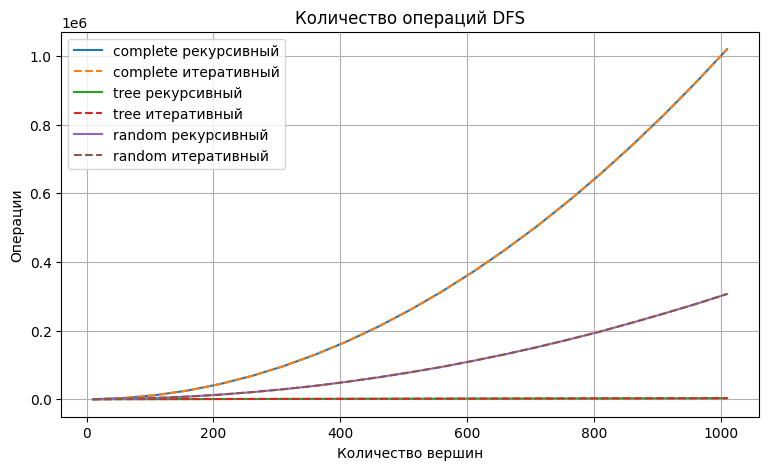

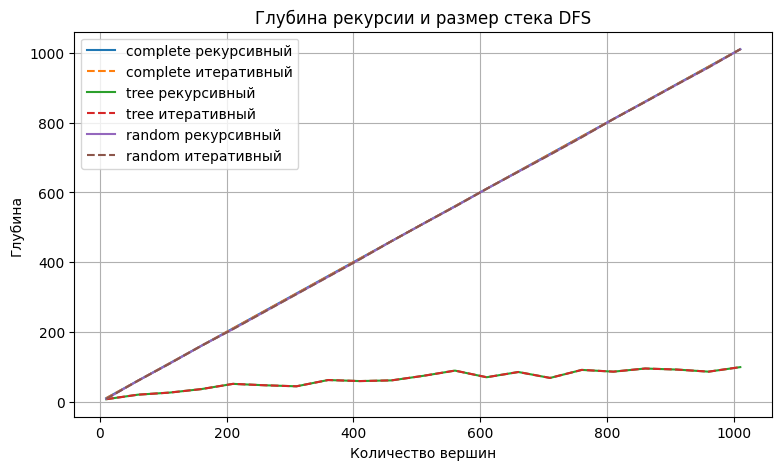

In [59]:
for metric_name, title in [
    ("operations", "Количество операций DFS"),
    ("memory", "Глубина рекурсии и размер стека DFS"),
]:
    plt.figure(figsize=(9, 5))

    for graph_type in graph_types:
        values = dfs_results[graph_type]

        if metric_name == "operations":
            recursive_values = values["recursive_operations"]
            iterative_values = values["iterative_operations"]
        else:
            recursive_values = values["recursive_depth"]
            iterative_values = values["iterative_stack"]

        plt.plot(
            values["sizes"], recursive_values,
            label=graph_type + " рекурсивный"
        )
        plt.plot(
            values["sizes"], iterative_values,
            linestyle="--", label=graph_type + " итеративный"
        )

    plt.xlabel("Количество вершин")
    plt.ylabel("Операции" if metric_name == "operations" else "Глубина")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()


**Ответьте на контрольные вопросы**

1. Какая асимптотическая сложность у DFS? Подтверждается ли она экспериментально?
2. Количество операций примерно одинаково для обеих реализаций? Почему?
3. Какая реализация быстрее? Почему? Какая реализация использует меньше памяти? При каких условиях рекурсивный DFS может упасть с ошибкой?
4. Как тип графа влияет на производительность?
4. Когда стоит использовать рекурсивный DFS?
6. Когда стоит использовать нерекурсивный DFS?
7. Какой способ лучше для очень глубоких графов?

In [60]:
recursive_total = 0
iterative_total = 0

for graph_type in graph_types:
    for value in dfs_results[graph_type]["recursive_seconds"]:
        recursive_total = recursive_total + value

    for value in dfs_results[graph_type]["iterative_seconds"]:
        iterative_total = iterative_total + value

if recursive_total < iterative_total:
    faster_dfs = "В этих замерах быстрее оказался рекурсивный DFS."
else:
    faster_dfs = "В этих замерах быстрее оказался итеративный DFS."

print(
    "1. Обе реализации работают за O(V + E); число проверок на графиках "
    "растёт пропорционально вершинам и ребрам.\n"
    "2. Число операций одинаково, потому что оба обхода посещают каждую "
    "вершину и проверяют каждое ребро.\n"
    + "3. " + faster_dfs + " Рекурсия хранит кадры вызовов, итеративный "
    "вариант — явный стек; рекурсивный вариант может превысить лимит "
    "глубины.\n"
    "4. Полный граф даёт больше проверок рёбер, чем дерево; случайный "
    "граф занимает промежуточное положение.\n"
    "5. Рекурсивный DFS удобен для небольших графов и короткой логики.\n"
    "6. Итеративный DFS удобен, когда важны контроль стека и отсутствие "
    "лимита рекурсии.\n"
    "7. Для очень глубоких графов безопаснее итеративная реализация."
)

1. Обе реализации работают за O(V + E); число проверок на графиках растёт пропорционально вершинам и ребрам.
2. Число операций одинаково, потому что оба обхода посещают каждую вершину и проверяют каждое ребро.
3. В этих замерах быстрее оказался рекурсивный DFS. Рекурсия хранит кадры вызовов, итеративный вариант — явный стек; рекурсивный вариант может превысить лимит глубины.
4. Полный граф даёт больше проверок рёбер, чем дерево; случайный граф занимает промежуточное положение.
5. Рекурсивный DFS удобен для небольших графов и короткой логики.
6. Итеративный DFS удобен, когда важны контроль стека и отсутствие лимита рекурсии.
7. Для очень глубоких графов безопаснее итеративная реализация.


# Задание 4 (2 балла)

Исследовать обхода графа в ширину BFS (нерекурсивный).

Реализуйте функцию обхода графа в ширину:

In [61]:
from collections import deque

def bfs_iterative(graph, start):
    """
    Нерекурсивный обход в ширину с использованием очереди

    Аргументы:
        graph: список смежности графа
        start: начальная вершина

    Возвращает:
        order: порядок обхода вершин
        operations: количество выполненных операций
        distances: расстояния от start до всех вершин
    """
    global bfs_max_queue_size
    n = len(graph)
    visited = [False] * n
    distances = [-1] * n
    order = []
    operations = 0
    bfs_max_queue_size = 0
    root_index = 0

    while root_index <= n:
        if root_index == 0:
            root = start
        else:
            root = root_index - 1

        if not visited[root]:
            queue = deque()
            queue.append(root)
            visited[root] = True

            if root == start:
                distances[root] = 0

            if len(queue) > bfs_max_queue_size:
                bfs_max_queue_size = len(queue)

            while queue:
                vertex = queue.popleft()
                order.append(vertex)
                operations = operations + 1

                for neighbor in graph[vertex]:
                    operations = operations + 1

                    if not visited[neighbor]:
                        visited[neighbor] = True
                        queue.append(neighbor)

                        if distances[vertex] != -1:
                            distances[neighbor] = distances[vertex] + 1

                        if len(queue) > bfs_max_queue_size:
                            bfs_max_queue_size = len(queue)

        root_index = root_index + 1

    return order, operations, distances

Используйте графы из ранее сгенерированного набора:
- `graphs_dataset/tree/`
- `graphs_dataset/random/`
- `graphs_dataset/complete/`

Для каждого графа от 10 до 1010 вершин с шагом 50 измеряем:

| Метрика | Как измеряем |
|---------|--------------|
| **Количество операций** | Счётчик в коде (посещения вершин, проверки рёбер) |

Не забудьте! Граф может быть не связным, а обойти его нужно весь.

In [62]:
bfs_results = {}

for graph_type in graph_types:
    graph_type_results = {
        "sizes": [],
        "operations": [],
        "average_queue": [],
        "largest_queue": [],
    }

    for n in graph_sizes:
        operations_total = 0
        queue_total = 0
        largest_queue = 0

        for file_path in dataset_files(graph_type, n):
            graph_n, adjacency = read_graph_file(file_path, "plain")
            order, operation_count, distances = bfs_iterative(adjacency, 0)

            if len(order) != graph_n:
                raise ValueError("BFS обошёл не все вершины")

            operations_total = operations_total + operation_count
            queue_total = queue_total + bfs_max_queue_size

            if bfs_max_queue_size > largest_queue:
                largest_queue = bfs_max_queue_size

        graph_type_results["sizes"].append(n)
        graph_type_results["operations"].append(
            operations_total / samples_per_size
        )
        graph_type_results["average_queue"].append(
            queue_total / samples_per_size
        )
        graph_type_results["largest_queue"].append(largest_queue)

    bfs_results[graph_type] = graph_type_results

Постройте график зависимости числа операций от размера графа.

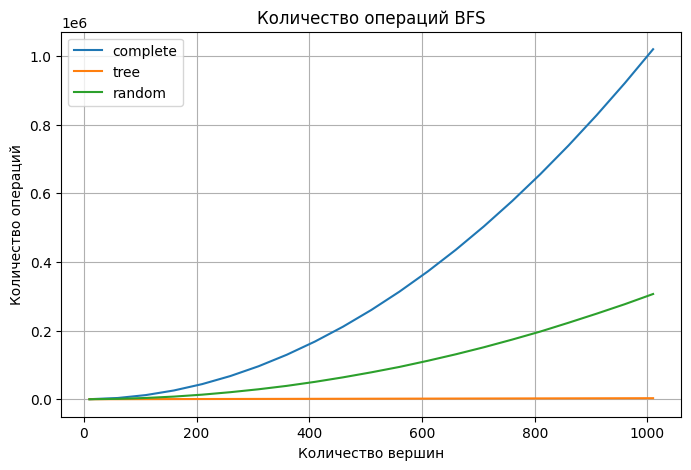

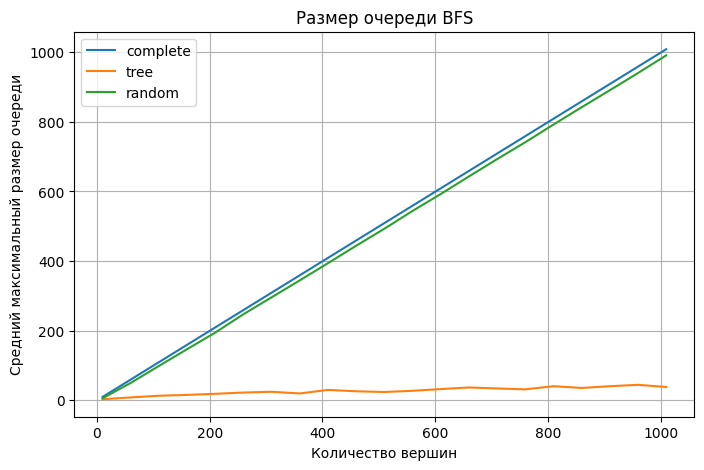

In [63]:
plt.figure(figsize=(8, 5))

for graph_type in graph_types:
    values = bfs_results[graph_type]
    plt.plot(values["sizes"], values["operations"], label=graph_type)

plt.xlabel("Количество вершин")
plt.ylabel("Количество операций")
plt.title("Количество операций BFS")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))

for graph_type in graph_types:
    values = bfs_results[graph_type]
    plt.plot(values["sizes"], values["average_queue"], label=graph_type)

plt.xlabel("Количество вершин")
plt.ylabel("Средний максимальный размер очереди")
plt.title("Размер очереди BFS")
plt.legend()
plt.grid(True)
plt.show()

**Ответьте на контрольные вопросы**

1. Какая асимптотическая сложность у BFS? Подтверждается ли она экспериментально?
2. Какой максимальный размер очереди для разных типов графов?
3. Почему для полного графа очередь быстро растёт?
4. Когда стоит использовать BFS? Когда стоит использовать DFS?

In [64]:
print(
    "1. BFS работает за O(V + E); график числа операций растёт вместе "
    "с количеством вершин и рёбер.\n"
    "2. Максимумы очереди на самом большом размере: "
    + "дерево — {} из 1010; случайный граф — {} из 1010; полный граф — "
    "{} из 1010. Значения измерены на сгенерированных образцах.\n"
    "3. В полном графе при обработке первой вершины BFS сразу добавляет "
    "в очередь почти все остальные вершины.\n"
    "4. BFS подходит для кратчайших путей в невзвешенных графах и "
    "обхода по слоям. DFS удобен для проверки связности, циклов и "
    "структуры графа."
    .format(
        bfs_results["tree"]["largest_queue"][-1],
        bfs_results["random"]["largest_queue"][-1],
        bfs_results["complete"]["largest_queue"][-1],
    )
)

1. BFS работает за O(V + E); график числа операций растёт вместе с количеством вершин и рёбер.
2. Максимумы очереди на самом большом размере: дерево — 42 из 1010; случайный граф — 993 из 1010; полный граф — 1009 из 1010. Значения измерены на сгенерированных образцах.
3. В полном графе при обработке первой вершины BFS сразу добавляет в очередь почти все остальные вершины.
4. BFS подходит для кратчайших путей в невзвешенных графах и обхода по слоям. DFS удобен для проверки связности, циклов и структуры графа.


# Задание 5 (3 балла)

В этом задании поработаем с поиском кратчайших путей и исследуем три алгоритма:
* Алгоритм Дейкстры (Dijkstra)
* Алгоритм Беллмана-Форда (Bellman-Ford)
* Алгоритм Флойда-Уоршелла (Floyd-Warshall)

Реализуйте функции для трёх алгоритмов. Обратите внимание на возвращаемые значения и подсчет операций.

In [65]:
import heapq
import math
from collections import deque

operations = 0

def dijkstra(adj_list, start):
    """
    Алгоритм Дейкстры для поиска кратчайших путей от start.

    Аргументы:
        adj_list: список смежности для ВЗВЕШЕННОГО графа.
                  Формат: adj_list[u] = [(v, weight), ...]
        start: начальная вершина.

    Возвращает:
        distances: список кратчайших расстояний от start до каждой вершины.
                   Если вершина недостижима, расстояние равно float('inf').
        operations: общее количество выполненных операций.
    """
    global operations
    n = len(adj_list)
    distances = [math.inf] * n
    distances[start] = 0
    priority_queue = [(0, start)]
    operations = 1

    while priority_queue:
        current_distance, vertex = heapq.heappop(priority_queue)
        operations = operations + 1

        if current_distance != distances[vertex]:
            continue

        for neighbor, weight in adj_list[vertex]:
            operations = operations + 1
            new_distance = current_distance + weight

            if new_distance < distances[neighbor]:
                distances[neighbor] = new_distance
                heapq.heappush(
                    priority_queue, (new_distance, neighbor)
                )
                operations = operations + 1

    return distances, operations

In [66]:
def bellman_ford(adj_list, start):
    """
    Алгоритм Беллмана-Форда для поиска кратчайших путей от start.

    Аргументы:
        adj_list: список смежности для ВЗВЕШЕННОГО графа.
                  Формат: adj_list[u] = [(v, weight), ...]
        start: начальная вершина.

    Возвращает:
        distances: список кратчайших расстояний от start до каждой вершины.
                   Если вершина недостижима, расстояние равно float('inf').
        has_negative_cycle: булево значение, указывающее, обнаружен ли цикл.
        operations: общее количество выполненных операций.
    """
    n = len(adj_list)
    distances = [math.inf] * n
    distances[start] = 0
    operation_count = 0

    for iteration in range(n - 1):
        changed = False

        for vertex in range(n):
            for neighbor, weight in adj_list[vertex]:
                operation_count = operation_count + 1

                if distances[vertex] != math.inf:
                    new_distance = distances[vertex] + weight

                    if new_distance < distances[neighbor]:
                        distances[neighbor] = new_distance
                        changed = True

        if not changed:
            break

    has_negative_cycle = False

    for vertex in range(n):
        for neighbor, weight in adj_list[vertex]:
            operation_count = operation_count + 1

            if distances[vertex] != math.inf:
                new_distance = distances[vertex] + weight

                if new_distance < distances[neighbor]:
                    has_negative_cycle = True
                    break

        if has_negative_cycle:
            break

    return distances, has_negative_cycle, operation_count

In [67]:
import numpy as np

def floyd_warshall(weight_matrix):
    """
    Алгоритм Флойда-Уоршелла для поиска кратчайших расстояний между парами.

    Аргументы:
        weight_matrix: квадратная матрица весов размера VxV.
                       weight_matrix[u][v] содержит вес ребра (u, v),
                       или float('inf'), если ребра нет.

    Возвращает:
        dist: итоговая матрица кратчайших расстояний.
        operations: общее количество выполненных операций.
    """
    distances = np.array(weight_matrix, dtype=float)
    n = len(weight_matrix)
    operation_count = 0

    for middle in range(n):
        through_middle = (
            distances[:, middle:middle + 1]
            + distances[middle:middle + 1, :]
        )
        distances = np.minimum(distances, through_middle)
        operation_count = operation_count + n * n

    result = distances.tolist()
    return result, operation_count

**Проведите эксперименты**

Используйте графы с количеством вершин от 10 до 1010 с шагом 50 (если для Флойда-Уоршела будет слишком долгий расчет, возьмете ограничение в 500).

Нужно провести эксперименты (то есть замерить число операций) для лучшего, среднего и худшего случая тремя алгоритмами.

In [68]:
shortest_path_results = {
    "dijkstra": {},
    "bellman_ford": {},
    "floyd_warshall": {},
}
floyd_sizes = []

for n in graph_sizes:
    if n <= 500:
        floyd_sizes.append(n)

for graph_type in graph_types:
    shortest_path_results["dijkstra"][graph_type] = {
        "sizes": [],
        "operations": [],
    }
    shortest_path_results["bellman_ford"][graph_type] = {
        "sizes": [],
        "operations": [],
    }
    shortest_path_results["floyd_warshall"][graph_type] = {
        "sizes": [],
        "operations": [],
    }

    for n in graph_sizes:
        dijkstra_total = 0
        bellman_total = 0

        for file_path in dataset_files(graph_type, n):
            graph_n, weighted_graph = read_graph_file(
                file_path, "weighted"
            )
            distances, dijkstra_operations = dijkstra(weighted_graph, 0)
            bellman_distances, has_negative_cycle, bellman_operations = (
                bellman_ford(weighted_graph, 0)
            )

            if has_negative_cycle:
                raise ValueError("Обнаружен отрицательный цикл")

            if distances != bellman_distances:
                raise ValueError("Дейкстра и Беллман-Форд не совпали")

            dijkstra_total = dijkstra_total + dijkstra_operations
            bellman_total = bellman_total + bellman_operations

        shortest_path_results["dijkstra"][graph_type]["sizes"].append(n)
        shortest_path_results["dijkstra"][graph_type][
            "operations"
        ].append(dijkstra_total / samples_per_size)
        shortest_path_results["bellman_ford"][graph_type]["sizes"].append(n)
        shortest_path_results["bellman_ford"][graph_type][
            "operations"
        ].append(bellman_total / samples_per_size)

        if n in floyd_sizes:
            floyd_total = 0

            for file_path in dataset_files(graph_type, n):
                graph_n, weighted_graph = read_graph_file(
                    file_path, "weighted"
                )
                weight_matrix = []
                first = 0

                while first < graph_n:
                    row = [math.inf] * graph_n
                    row[first] = 0
                    weight_matrix.append(row)
                    first = first + 1

                for first in range(graph_n):
                    for second, weight in weighted_graph[first]:
                        weight_matrix[first][second] = weight

                all_distances, floyd_operations = floyd_warshall(
                    weight_matrix
                )
                floyd_total = floyd_total + floyd_operations

            shortest_path_results["floyd_warshall"][graph_type][
                "sizes"
            ].append(n)
            shortest_path_results["floyd_warshall"][graph_type][
                "operations"
            ].append(floyd_total / samples_per_size)

**Графики**

Постройте графики для каждого из трех алгоритмов (Дейкстра, Беллман-Форд, Флойд-Уоршелл), показывающие зависимость количества операций от размера графа (V) для разных типов графов.

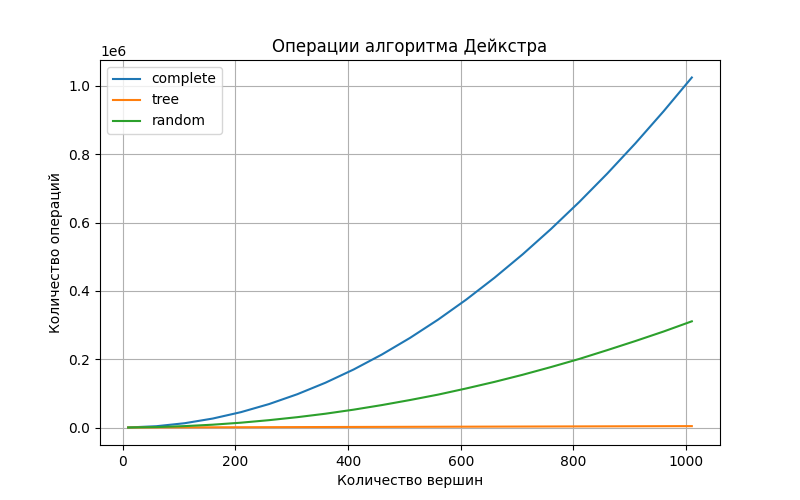

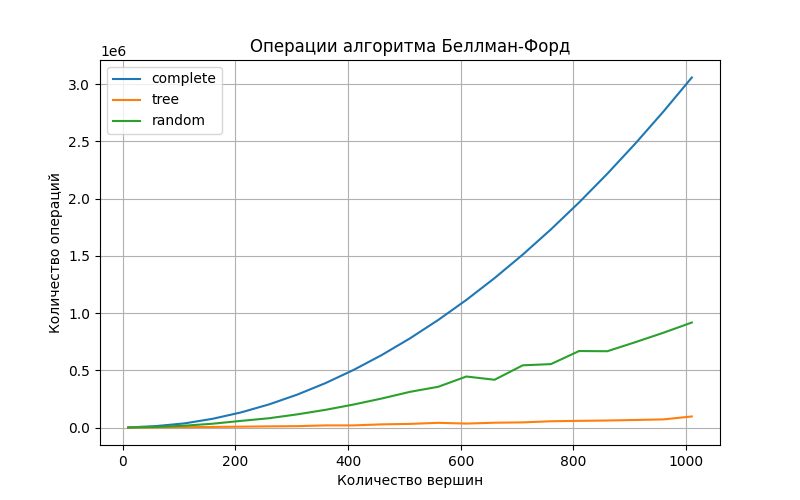

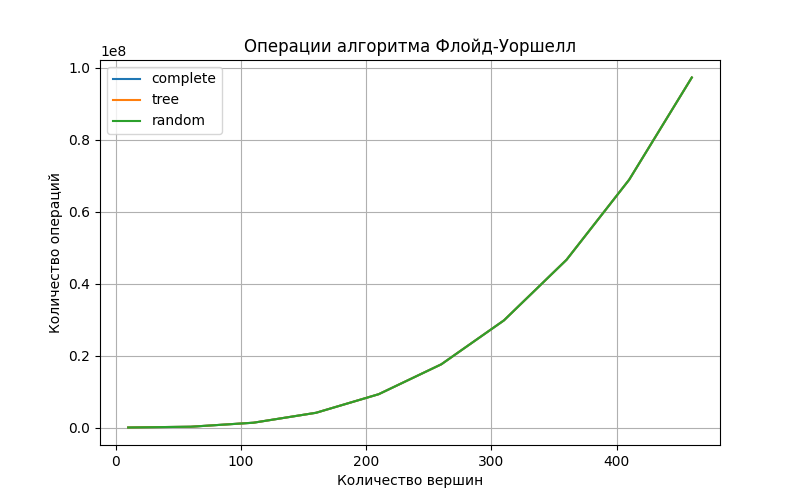

In [69]:
algorithm_titles = {
    "dijkstra": "Дейкстра",
    "bellman_ford": "Беллман-Форд",
    "floyd_warshall": "Флойд-Уоршелл",
}

for algorithm_name in ["dijkstra", "bellman_ford", "floyd_warshall"]:
    plt.figure(figsize=(8, 5))

    for graph_type in graph_types:
        values = shortest_path_results[algorithm_name][graph_type]
        plt.plot(
            values["sizes"], values["operations"], label=graph_type
        )

    plt.xlabel("Количество вершин")
    plt.ylabel("Количество операций")
    plt.title("Операции алгоритма " + algorithm_titles[algorithm_name])
    plt.legend()
    plt.grid(True)
    plt.show()

**Контрольные вопросы**

1. Совпадают ли результаты экспериментов с теоретической оценкой сложности алгоритмов? Почему?

2. На каких графах Дейкстра работает быстрее? Когда использование Беллмана-Форда является необходимостью (даже если он медленнее)?

3. Представьте, что нужно найти расстояния кратчайшие между всеми парами вершин. Для какого типа графов (плотных или разреженных) выгоднее запустить алгоритм Дейкстры из каждой вершины, а для каких — использовать Флойда-Уоршелла? Почему?

In [70]:
print(
    "1. Дейкстра на списке смежности зависит от числа ребер и операций "
    "с кучей; Беллман-Форд делает до V проходов по ребрам; "
    "Флойд-Уоршелл имеет кубическую зависимость от V.\n"
    "2. Дэйкстра особенно эффективна на разреженных графах с "
    "неотрицательными весами. Беллман-Форд нужен при отрицательных "
    "весах и также позволяет обнаружить достижимый отрицательный цикл.\n"
    "3. Для всех пар в разреженном графе выгодно запускать Дэйкстру "
    "из каждой вершины: это примерно O(VE log V). Для плотного графа "
    "часто удобнее Флойд-Уоршелл за O(V^3), который сразу находит "
    "расстояния между всеми парами.\n"
    "Флойд-Уоршелл в этой работе ограничен 500 вершинами из-за "
    "кубической сложности; Дэйкстра и Беллман-Форд проверены на всех "
    "размерах набора."
)

1. Дейкстра на списке смежности зависит от числа ребер и операций с кучей; Беллман-Форд делает до V проходов по ребрам; Флойд-Уоршелл имеет кубическую зависимость от V.
2. Дэйкстра особенно эффективна на разреженных графах с неотрицательными весами. Беллман-Форд нужен при отрицательных весах и также позволяет обнаружить достижимый отрицательный цикл.
3. Для всех пар в разреженном графе выгодно запускать Дэйкстру из каждой вершины: это примерно O(VE log V). Для плотного графа часто удобнее Флойд-Уоршелл за O(V^3), который сразу находит расстояния между всеми парами.
Флойд-Уоршелл в этой работе ограничен 500 вершинами из-за кубической сложности; Дэйкстра и Беллман-Форд проверены на всех размерах набора.
